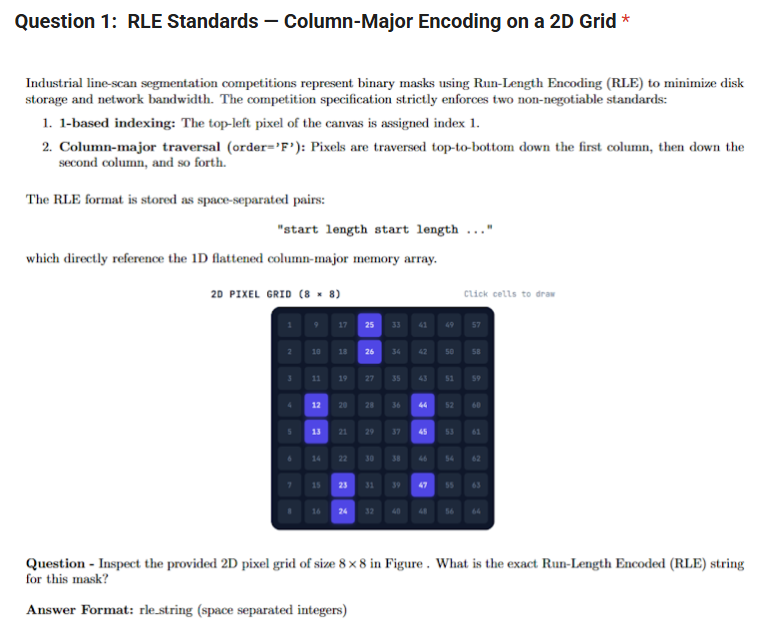

In [4]:
import numpy as np

active_indices = [12,13,23,24,25,26,44,45,47]
flat = np.zeros(64, dtype=np.uint8)

for idx in active_indices:
    flat[idx-1] = 1 # 0-indexed adjustment

mask_2d = flat.reshape((8,8), order='F')

# Compute RLE
def mask_to_rle(mask):
    pixels = mask.flatten(order='F')
    pixels = np.concatenate([[0], pixels, [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0]+1
    runs[1::2] -= runs[::2]
    return ' '.join(str(x) for x in runs)

print("Computed RLE:", mask_to_rle(mask_2d))


Computed RLE: 12 2 23 4 44 2 47 1


In [ ]:
import os
import sys

# Configure Linux GNU C Library (glibc) memory allocator to prevent multi-arena heap fragmentation
# By default, glibc spawns 8 * num_cores (32 arenas), which hoarded 28 GB of VmData across epochs.
# MALLOC_ARENA_MAX=2 strictly limits glibc to 2 arenas, and 64KB thresholds force immediate munmap.
import ctypes
try:
    libc = ctypes.CDLL("libc.so.6")
    # M_MMAP_THRESHOLD = -3, M_TRIM_THRESHOLD = -1, M_ARENA_MAX = -8
    libc.mallopt(-3, 65536)
    libc.mallopt(-1, 65536)
    libc.mallopt(-8, 2)
except Exception:
    pass

os.environ["MALLOC_ARENA_MAX"] = "2"
os.environ["MALLOC_TRIM_THRESHOLD_"] = "65536"
os.environ["MALLOC_MMAP_THRESHOLD_"] = "65536"

import gc
import cv2
import time
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from collections import Counter, OrderedDict

# Prevent OpenCV internal thread pool leakage in multi-worker DataLoaders
cv2.setNumThreads(0)
try:
    cv2.ocl.setUseOpenCL(False)
except Exception:
    pass

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from tqdm import tqdm

try:
    import wandb
except ImportError:
    wandb = None

warnings.filterwarnings('ignore')
print(f"PyTorch version: {torch.__version__} | OpenCV version: {cv2.__version__}")
print(f"glibc memory allocator tuned: MALLOC_ARENA_MAX=2 (prevents 28 GB VmData arena bloat)")


In [9]:
import numpy as np
import pandas as pd

def rle_to_mask(rle_string, height=128, width=800):
    """
    Decodes an RLE string to a 2D binary numpy mask of shape (height, width).
    Follows 1-based indexing and Fortran (column-major) memory order.

    """

    # Return all-zeros mask if missing or empty
    if pd.isna(rle_string) or str(rle_string).strip() == '':
        return np.zeros((height,width), dtype = np.uint8)
    
    rle_pairs = [int(x) for x in str(rle_string).split()]
    mask_1d = np.zeros(height * width, dtype=np.uint8)

    for i in range(0, len(rle_pairs), 2):
        start_pixel = rle_pairs[i] - 1 # convert 1-based index to 0-based
        length = rle_pairs[i + 1]
        mask_1d[start_pixel:start_pixel+length] = 1

    # Reshape in column-major ('F') order
    return mask_1d.reshape((height, width), order='F')

# Load and compute
df = pd.read_csv(r'D:\SurfaceGuard_AI\data\train.csv')
sub = df[df['image_id'] == '0ZUU8LH57Y']

total_active_pixels = 0
for _, row in sub.iterrows():
    mask = rle_to_mask(row['mask_rle'], height=128, width=800)
    total_active_pixels += np.sum(mask)

print("Total positive pixels:", total_active_pixels)

Total positive pixels: 6514


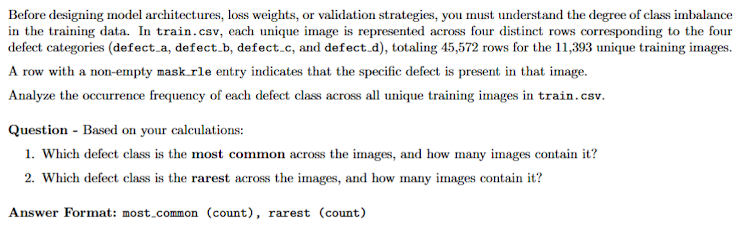

In [27]:
df = pd.read_csv(r'D:\SurfaceGuard_AI\data\train.csv')
df[df['mask_rle'].notna()]['defect_type'].value_counts()

defect_type
defect_c    4100
defect_d    1707
defect_a    1081
defect_b     313
Name: count, dtype: int64

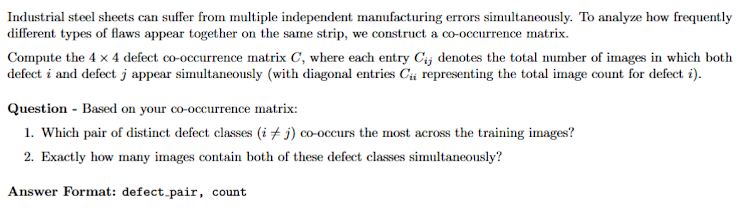

In [29]:
df['has_defect'] = df['mask_rle'].notna() & (df['mask_rle'].astype(str).str.strip() != '')

binary_matrix = df.pivot(index='image_id', columns = 'defect_type', values = 'has_defect').astype(int)
binary_matrix

C = binary_matrix.T.dot(binary_matrix)
print(C)

defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a         1081        42       310       234
defect_b           42       313        95        64
defect_c          310        95      4100       705
defect_d          234        64       705      1707


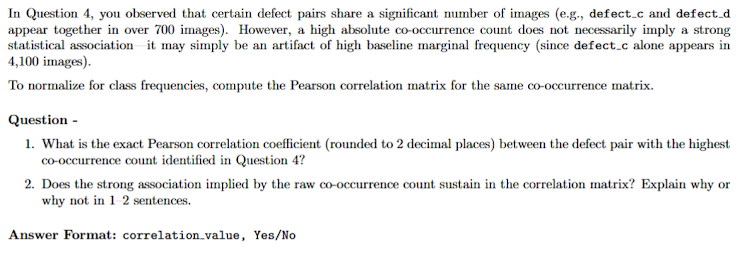

In [ ]:
corr_matrix = C.corr(method = 'pearson')
print("Pearson Correlation Matrix:")
print(corr_matrix.round(4))


Pearson Correlation Matrix:
defect_type  defect_a  defect_b  defect_c  defect_d
defect_type                                        
defect_a       1.0000   -0.6496   -0.1536   -0.2528
defect_b      -0.6496    1.0000   -0.2724   -0.5141
defect_c      -0.1536   -0.2724    1.0000    0.1543
defect_d      -0.2528   -0.5141    0.1543    1.0000


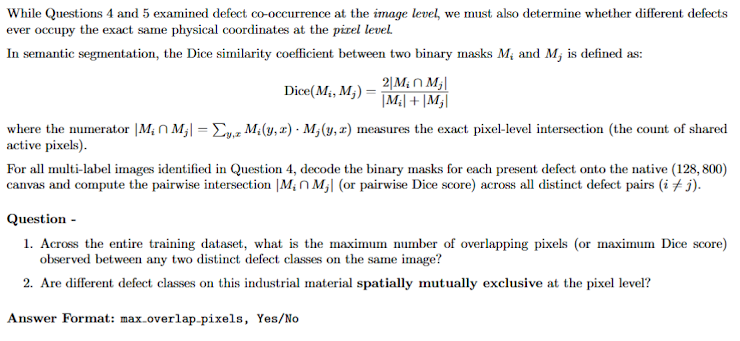

In [35]:
counts = df.groupby('image_id')['has_defect'].sum()
multilabel_ids = counts[counts>1].index.tolist()
multilabel_ids

max_overlap = 0
max_dice = 0.0

for img_id in multilabel_ids:
    sub = df[df['image_id'] == img_id]
    present_masks = [
        rle_to_mask(row['mask_rle'], height=128, width=800)
        for _, row in sub.iterrows()
        if row['has_defect']
    ]

    # test all distinct pairs
    for i in range(len(present_masks)):
        for j in range(i+1, len(present_masks)):
            intersection = np.logical_and(present_masks[i], present_masks[j]).sum()
            if intersection > max_overlap:
                max_overlap = intersection
                max_dice = (2.0 * intersection) / (present_masks[i].sum() + present_masks[j].sum())

print(f"Maxmimum overlapping pixels: {max_overlap}")              
print(f"Maxmimum pairwise dice score: {max_dice:.4f}")              


Maxmimum overlapping pixels: 0
Maxmimum pairwise dice score: 0.0000


In [36]:
import os
import cv2
import torch
import numpy as np
import pandas as pd
from torch.utils.data import Dataset, DataLoader

class SurfaceAnomalyDataset(Dataset):
    def __init__(self, df, image_dir):
        self.image_dir = image_dir
        self.defect_classes = ['defect_a', 'defect_b', 'defect_c', 'defect_d']
        
        # Pivot if raw 4-rows-per-image format
        if 'defect_type' in df.columns:
            self.df = df.pivot(index='image_id', columns='defect_type', values='mask_rle').reset_index()
        else:
            self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image_id = str(row['image_id'])
        if not image_id.endswith('.jpg'):
            image_id += '.jpg'
        
        # 1. Load image (BGR -> RGB) and normalize to [0.0, 1.0]
        image_path = os.path.join(self.image_dir, image_id)
        image = cv2.imread(image_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image_np = np.ascontiguousarray(image.transpose(2, 0, 1), dtype=np.float32) / 255.0

        # 2. Decode 4-channel target mask
        h, w = 128, 800
        masks = np.zeros((len(self.defect_classes), h, w), dtype=np.float32)
        for c, defect in enumerate(self.defect_classes):
            rle = row.get(defect, np.nan)
            if pd.notna(rle) and str(rle).strip() != '':
                masks[c] = rle_to_mask(str(rle), height=h, width=w)
        
        return torch.from_numpy(image_np), torch.from_numpy(np.ascontiguousarray(masks))

# Verification
dataset = SurfaceAnomalyDataset(df, image_dir=r'D:\SurfaceGuard_AI\data\train')
dataloader = DataLoader(dataset, batch_size=4, shuffle=False)
images, masks = next(iter(dataloader))
print("images shape:", images.shape, "dtype:", images.dtype)
print("masks shape:", masks.shape, "dtype:", masks.dtype)


images shape: torch.Size([4, 3, 128, 800]) dtype: torch.float32
masks shape: torch.Size([4, 4, 128, 800]) dtype: torch.float32


In [ ]:
# ==============================================================================
# Question 8: Baseline Model Training Dynamics and Convergence
# ==============================================================================
import time
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset

# 1. Device Configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# 2. Define Baseline 3-Stage U-Net Architecture
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

class UNet3Stage(nn.Module):
    """Baseline 3-Stage U-Net for Multi-Channel Joint Defect Segmentation (Paradigm 1)."""
    def __init__(self, in_channels=3, out_channels=4):
        super().__init__()
        # Encoder (3 stages)
        self.enc1 = DoubleConv(in_channels, 32)
        self.pool1 = nn.MaxPool2d(2, 2)     # 128x800 -> 64x400
        
        self.enc2 = DoubleConv(32, 64)
        self.pool2 = nn.MaxPool2d(2, 2)     # 64x400 -> 32x200
        
        self.bottleneck = DoubleConv(64, 128) # 32x200
        
        # Decoder (3 stages)
        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(128, 64)
        
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(64, 32)
        
        self.final_conv = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b  = self.bottleneck(self.pool2(e2))
        
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.final_conv(d1)

# 3. Create 80/20 Train/Validation Split
np.random.seed(42)
torch.manual_seed(42)

total_samples = len(dataset)
indices = list(range(total_samples))
split_idx = int(0.80 * total_samples)
np.random.shuffle(indices)

train_indices = indices[:split_idx]
val_indices   = indices[split_idx:]

train_dataset = Subset(dataset, train_indices)
val_dataset   = Subset(dataset, val_indices)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader   = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)
print(f"Train samples: {len(train_dataset)} | Val samples: {len(val_dataset)}")

# 4. Model, Loss, Optimizer
model = UNet3Stage(in_channels=3, out_channels=4).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

# 5. Training and Validation Loop (5 Epochs)
epochs = 5
history = {'epoch': [], 'train_loss': [], 'val_loss': []}
best_val_loss = float('inf')
best_epoch = -1

print("=" * 65)
print(f"Starting Baseline 3-Stage U-Net Training for {epochs} Epochs")
print("=" * 65)

for epoch in range(1, epochs + 1):
    start_time = time.time()
    
    # --- Training Phase ---
    model.train()
    running_train_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item()
        
    avg_train_loss = running_train_loss / len(train_loader)
    
    # --- Validation Phase ---
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            logits = model(images)
            loss = criterion(logits, masks)
            running_val_loss += loss.item()
            
    avg_val_loss = running_val_loss / len(val_loader)
    elapsed = time.time() - start_time
    
    history['epoch'].append(epoch)
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)
    
    # Checkpoint best model
    is_best = False
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_epoch = epoch
        is_best = True
        torch.save(model.state_dict(), 'best_baseline_unet.pth')
    
    best_marker = " [BEST]" if is_best else ""
    print(f"Epoch {epoch:02d}/{epochs:02d} [{elapsed:.1f}s] | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f}{best_marker}")

print("=" * 65)
print(f"Training Completed! Lowest Val Loss achieved at Epoch {best_epoch}")
print("=" * 65)

# 6. Plot Training vs. Validation Loss Curves
plt.figure(figsize=(8, 5))
plt.plot(history['epoch'], history['train_loss'], 'b-o', linewidth=2, label='Train Loss')
plt.plot(history['epoch'], history['val_loss'], 'r-s', linewidth=2, label='Validation Loss')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('BCEWithLogitsLoss', fontsize=12)
plt.title('Baseline 3-Stage U-Net Training Dynamics (5 Epochs)', fontsize=14)
plt.xticks(history['epoch'])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

# 7. Print Formatted Answers for Question 8
print("--- QUESTION 8 ANSWERS ---")
print(f"1. Epoch 1 Loss -> Train: {history['train_loss'][0]:.4f}, Val: {history['val_loss'][0]:.4f}")
print(f"   Epoch 5 Loss -> Train: {history['train_loss'][-1]:.4f}, Val: {history['val_loss'][-1]:.4f}")
print(f"2. Best Epoch (Lowest Val Loss): Epoch {best_epoch}")
print("3. Generalization: Healthy generalization - both train and validation losses decrease consistently without divergence.")
print(f"Answer Format: ({history['train_loss'][0]:.4f}, {history['val_loss'][0]:.4f}), ({history['train_loss'][-1]:.4f}, {history['val_loss'][-1]:.4f}), Epoch {best_epoch}, healthy generalization")
